# Example notebook of CAPE-K analysis



In [1]:
# Load in your packages. 
import sys
import os
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import numpy as np
from datetime import datetime
import xarray as xr
import iris
import cartopy.crs as ccrs
import pandas as pd
import seaborn as sns
import matplotlib.dates as mdates
from geopy.distance import geodesic
from glob import glob

In [2]:
# This will adjust the compute resources to have more memory on a single worker (CPU). 
# The type of analysis we are doing here - we don't really need paralelle computing, and in fact that would likely slow it down. 

from dask.distributed import Client, LocalCluster

jobfs = os.environ["PBS_JOBFS"]

cluster = LocalCluster(
    n_workers=1,
    threads_per_worker=1,
    memory_limit="9GiB", # change the memory - depending on how much you requested. 
    local_directory=jobfs,
)

client = Client(cluster)

In [3]:
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /proxy/8787/status,
Dashboard: /proxy/8787/status,Workers: 1
Total threads: 1,Total memory: 9.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:42023,Workers: 0
Dashboard: /proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:42517,Total threads: 1
Dashboard: /proxy/40971/status,Memory: 9.00 GiB
Nanny: tcp://127.0.0.1:34143,


# Define your constants first: 
Things that are the same throughout the notebook


In [4]:
data_dir = '/g/data/gx60/experiments/2026-09-07_cape-k_coast-k/u-by395/'
kcglat = -40.683
kcglon = 144.698

# Data: 
Here we:  
- set up the code to read in the model data
- read in the obervational data that we will use thoughout (eg. ship track)

In [5]:
# this is a function to be used with the xarray open functions. It tells the function to only 
# extract the data at the specific latitude and longitude defined. 

def preprocess(ds):
    return ds.sel(longitude=kcglon,latitude=kcglat,method='nearest')

In [6]:
# Coast-K ship track
underway = pd.read_csv('/g/data/jk72/slf563/OBS/campaigns/COAST-K/MNF_IN2025_V03_uwy_trawler/MNF_IN2025_V03_uwy_trawler.csv',index_col=1) # read in data
underway.index = pd.DatetimeIndex(underway.index) # convert time to useful format
underway = underway.drop(columns=['Survey','MarLIN UUID']) # dope the columns we dont need/that cause troupble
underway_hourly = underway.resample('h').mean() # resample to be every hour (for plotting)

In [7]:
# list all the fields that is held in the underway data
list(underway_hourly.keys())

['Latitude',
 'Longitude',
 'Position QC',
 'Project',
 'MarLIN',
 'MAAP_STATUS',
 'MAAP_STATUS_QC',
 'AIR_PRESSURE',
 'AIR_PRESSURE_QC',
 'ALTITUDE',
 'ALTITUDE_QC',
 'AIR_TEMP',
 'AIR_TEMP_QC',
 'PCO2_CONDENSER_TEMPERATURE',
 'PCO2_CONDENSER_TEMPERATURE_QC',
 'COURSE_OG',
 'COURSE_OG_QC',
 'DEPTH',
 'DEPTH_QC',
 'OXYGEN',
 'OXYGEN_QC',
 'PCO2_EQUILIBRATOR_PRESSURE',
 'PCO2_EQUILIBRATOR_PRESSURE_QC',
 'FLUORESCENCE',
 'FLUORESCENCE_QC',
 'HUMIDITY',
 'HUMIDITY_QC',
 'PCO2_LICOR_FLOW',
 'PCO2_LICOR_FLOW_QC',
 'PCO2_LICOR_PRESSURE',
 'PCO2_LICOR_PRESSURE_QC',
 'IMOS_MAX_WIND_GUST',
 'IMOS_MAX_WIND_GUST_QC',
 'WIND_GUST',
 'WIND_GUST_QC',
 'AIR_SAMPLING_INLET_MODE',
 'AIR_SAMPLING_INLET_MODE_QC',
 'OPTODE_WATER_TEMP',
 'OPTODE_WATER_TEMP_QC',
 'OXYGEN_SATURATION',
 'OXYGEN_SATURATION_QC',
 'PAR',
 'PAR_QC',
 'PORT_DEW_POINT',
 'PORT_DEW_POINT_QC',
 'PCO2_PUMP_SPEED',
 'PCO2_PUMP_SPEED_QC',
 'IMOS_STBD_PYRANOMTR',
 'IMOS_STBD_PYRANOMTR_QC',
 'IMOS_PORT_PYRANOMTR',
 'IMOS_PORT_PYRANOMTR_QC

# Plot a map of the model domain 
Make a plot showing the inner model domain (at 1km resolution), the location of KCG and the RVI. We have also plotted the topography over land points and the sea surface temperaure over ocean points. 

# Things you could try: 
- Plot MSLP contours over the map
- Zoom in on region where ship/station are
- Change colour maps of SSTs/topo

In [8]:
# read in the topography data 
topo = xr.open_dataset(data_dir+'20250505T1200Z/Southern_Ocean_ERA5to1km_d0100_RAL3P3/SLV/topog-Southern_Ocean_ERA5to1km_d0100_RAL3P3-v1.nc')

/jobfs/182535723.gadi-pbs/ipykernel_2755204/2162051163.py:2: FutureWarning: In a future version, xarray will not decode the variable 'forecast_period' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will rely on the presence of a timedelta64 'dtype' attribute, which is now xarray's default way of encoding timedelta64 values.
To continue decoding into a timedelta64 dtype, either set `decode_timedelta=True` when opening this dataset, or add the attribute `dtype='timedelta64[ns]'` to this variable on disk.
To opt-in to future behavior, set `decode_timedelta=False`.
  topo = xr.open_dataset(data_dir+'20250505T1200Z/Southern_Ocean_ERA5to1km_d0100_RAL3P3/SLV/topog-Southern_Ocean_ERA5to1km_d0100_RAL3P3-v1.nc')


In [9]:
# read in the SSTs (just taking data from the first day)
sst = iris.load(data_dir+'20250505T1200Z/Southern_Ocean_ERA5to1km_d0100_RAL3P3/OSTIA/ostia_sst.anc')
sst = xr.DataArray.from_iris(sst[1])

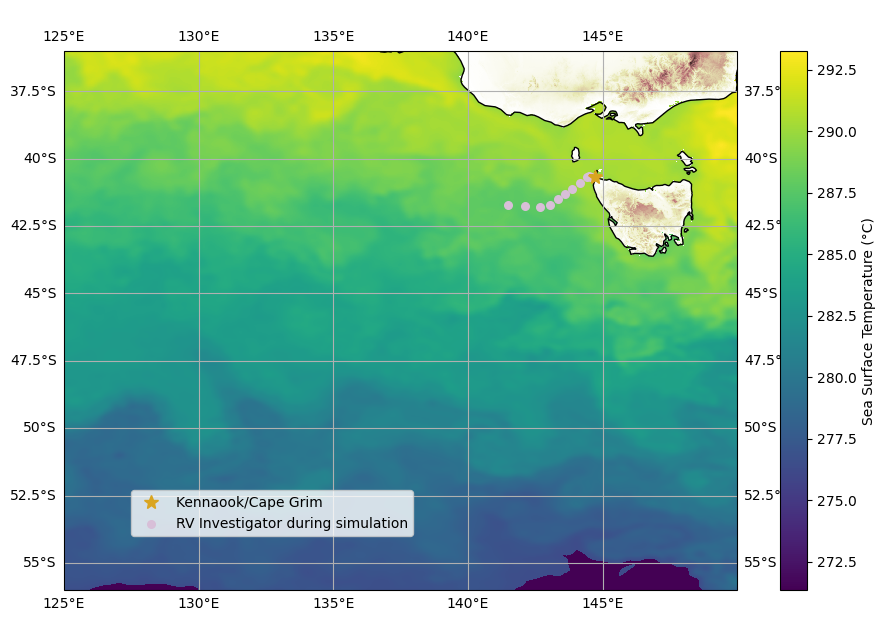

In [10]:
#Cape Grim/default 

fig = plt.figure(figsize=(11,7))

ax = plt.subplot(111, projection=ccrs.PlateCarree()) # set up map projection                  
ax.coastlines();
ax.gridlines(draw_labels=True)

# Set up colourmaps 
cm = sns.color_palette('pink_r',as_cmap=True)
cmap_sst = sns.color_palette("viridis", as_cmap=True)
cmap_sst.set_bad(alpha=0)  # ← transparency on NaNs

# Plot topography and ssts 
topo['topog'].where(topo['topog'] !=0, np.nan).plot(transform=ccrs.PlateCarree(),cmap=cm,add_colorbar=False)
sst.where(sst !=0, np.nan).plot(transform=ccrs.PlateCarree(),cmap=cmap_sst,add_colorbar=True,cbar_kwargs={'label': 'Sea Surface Temperature (°C)'})

# plot KCG location
plt.plot(kcglon,kcglat,marker='*',linestyle='None',label='Kennaook/Cape Grim',color='goldenrod',markersize=10); 

# Plot ship track 
p = plt.scatter(underway_hourly.Longitude[::3].loc['2025-05-05 12:00':'2025-05-08 12:00'],
                underway_hourly.Latitude[::3].loc['2025-05-05 12:00':'2025-05-08 12:00'],
                c='thistle',s=30,alpha=1,
                transform=ccrs.PlateCarree(),label='RV Investigator during simulation')

plt.title(' ')

plt.legend(loc=[0.1,0.1]);

# Automatic weather station data

Plot some basic meteorology for the CAPE-K data against the model 
- pressure
- humidity
- temperature
- Also over lay times when we have weather baloon launches

### Things to try: 
- plot the wind speed and direction
- plot the dew point temperature


In [11]:
# open the model's met data - see how we use the preprocess function
sfc_temp = xr.open_mfdataset(data_dir+'*/Southern_Ocean_ERA5to1km_d0100_RAL3P3/SPEC/sfc_temp-Southern_Ocean_ERA5to1km_d0100_RAL3P3-v1-*.nc',preprocess=preprocess)
sfc_hum = xr.open_mfdataset(data_dir+'*/Southern_Ocean_ERA5to1km_d0100_RAL3P3/SPEC/spec_hum-Southern_Ocean_ERA5to1km_d0100_RAL3P3-v1-*.nc',preprocess=preprocess)
sfc_pres = xr.open_mfdataset(data_dir+'*/Southern_Ocean_ERA5to1km_d0100_RAL3P3/SPEC/pressure-Southern_Ocean_ERA5to1km_d0100_RAL3P3-v1-*.nc',preprocess=preprocess)

/jobfs/182535723.gadi-pbs/ipykernel_2755204/3943044554.py:2: FutureWarning: In a future version, xarray will not decode the variable 'forecast_period' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will rely on the presence of a timedelta64 'dtype' attribute, which is now xarray's default way of encoding timedelta64 values.
To continue decoding into a timedelta64 dtype, either set `decode_timedelta=True` when opening this dataset, or add the attribute `dtype='timedelta64[ns]'` to this variable on disk.
To opt-in to future behavior, set `decode_timedelta=False`.
  sfc_temp = xr.open_mfdataset(data_dir+'*/Southern_Ocean_ERA5to1km_d0100_RAL3P3/SPEC/sfc_temp-Southern_Ocean_ERA5to1km_d0100_RAL3P3-v1-*.nc',preprocess=preprocess)
/jobfs/182535723.gadi-pbs/ipykernel_2755204/3943044554.py:2: FutureWarning: In a future version, xarray will not decode the variable 'forecast_period' into a timedelta64 dtype based on the presence of a tim

In [12]:
# take a look at the data
sfc_temp

<xarray.Dataset> Size: 16kB
Dimensions:                  (time: 576)
Coordinates:
  * time                     (time) datetime64[ns] 5kB 2025-05-05T12:10:00 .....
    forecast_reference_time  (time) datetime64[ns] 5kB 2025-05-05T12:00:00 .....
    forecast_period          (time) timedelta64[ns] 5kB dask.array<chunksize=(72,), meta=np.ndarray>
    latitude                 float64 8B -40.68
    longitude                float64 8B 144.7
Data variables:
    sfc_temp                 (time) float32 2kB dask.array<chunksize=(72,), meta=np.ndarray>
Attributes: (12/40)
    source:                         Data from Met Office Unified Model
    um_version:                     13.5
    geospatial_lat_min:             -56.0
    geospatial_lat_max:             -36.010002
    geospatial_lat_resolution:      0.009999999
    geospatial_lat_resolution_min:  0.009994507
    ...                             ...
    packing_accuracy:               -99
    zlib:                           True
    compression_level:              1
    shuffle:                        True
    fletcher32:                     True
    chunksizes:                     [72 56 65]

In [13]:
# Open the AWS station data from CAPE-K
aws = xr.open_mfdataset('/g/data/jk72/slf563/OBS/campaigns/CAPE-K/kcgmawsM1.b1/kcgmawsM1.b1.*.nc')
aws = aws.sel(time=sfc_pres.time.values,method = 'nearest')

/jobfs/182535723.gadi-pbs/ipykernel_2755204/2884756634.py:2: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  aws = xr.open_mfdataset('/g/data/jk72/slf563/OBS/campaigns/CAPE-K/kcgmawsM1.b1/kcgmawsM1.b1.*.nc')


In [14]:
# take a look at the data
aws

<xarray.Dataset> Size: 58kB
Dimensions:                           (time: 576, bound: 2)
Coordinates:
  * time                              (time) datetime64[ns] 5kB 2025-05-05T12...
Dimensions without coordinates: bound
Data variables: (12/18)
    base_time                         (time) datetime64[ns] 5kB 2025-05-05 .....
    time_offset                       (time) datetime64[ns] 5kB dask.array<chunksize=(576,), meta=np.ndarray>
    time_bounds                       (time, bound) datetime64[ns] 9kB dask.array<chunksize=(576, 2), meta=np.ndarray>
    atmospheric_pressure              (time) float32 2kB dask.array<chunksize=(576,), meta=np.ndarray>
    qc_atmospheric_pressure           (time) int32 2kB dask.array<chunksize=(576,), meta=np.ndarray>
    atmospheric_temperature           (time) float32 2kB dask.array<chunksize=(576,), meta=np.ndarray>
    ...                                ...
    qc_wind_speed                     (time) int32 2kB dask.array<chunksize=(576,), meta=np.ndarray>
    wind_direction                    (time) float32 2kB dask.array<chunksize=(576,), meta=np.ndarray>
    qc_wind_direction                 (time) int32 2kB dask.array<chunksize=(576,), meta=np.ndarray>
    lat                               (time) float32 2kB -40.68 ... -40.68
    lon                               (time) float32 2kB 144.7 144.7 ... 144.7
    alt                               (time) float32 2kB 80.0 80.0 ... 80.0 80.0
Attributes: (12/13)
    command_line:          maws_ingest -s kcg -f M1 --max-runtime 0
    Conventions:           ARM-1.3
    process_version:       ingest-maws-1.2-1.el9
    dod_version:           maws-b1-2.0
    input_source:          /data/collection/kcg/kcgmawsM1.00/LOG1_20250504.txt
    site_id:               kcg
    ...                    ...
    facility_id:           M1
    data_level:            b1
    location_description:  Kennaook/Cape Grim (KCG), Tasmania, Australia
    datastream:            kcgmawsM1.b1
    doi:                   10.5439/1162061
    history:               created by user armflowprod on machine prod-slurmn...

In [15]:
# need to caltulate relative humidity from specific humidity: 
# Vapor pressure
e = sfc_hum['spec_hum'] * sfc_pres['pressure']/100 / (0.622 + 0.378 * sfc_hum['spec_hum'] )

# Saturation vapor pressure
es = 6.112 * np.exp((17.67 * (sfc_temp['sfc_temp']-273.15)) / ((sfc_temp['sfc_temp']-273.15) + 243.5))

# Relative humidity
sfc_RH = 100 * e / es

In [16]:
# Need a list of the weather baloon files to read in later: 

#files = glob("/g/data/jk72/slf563/OBS/campaigns/CAPE-K/kcgsondewnpnM1.b1/*.cdf") # All files 
files=['/g/data/jk72/slf563/OBS/campaigns/CAPE-K/kcgsondewnpnM1.b1/kcgsondewnpnM1.b1.20250506.113000.cdf', # or just 4 specific times
       '/g/data/jk72/slf563/OBS/campaigns/CAPE-K/kcgsondewnpnM1.b1/kcgsondewnpnM1.b1.20250506.150000.cdf',
       '/g/data/jk72/slf563/OBS/campaigns/CAPE-K/kcgsondewnpnM1.b1/kcgsondewnpnM1.b1.20250506.180000.cdf',
       '/g/data/jk72/slf563/OBS/campaigns/CAPE-K/kcgsondewnpnM1.b1/kcgsondewnpnM1.b1.20250506.210000.cdf',]


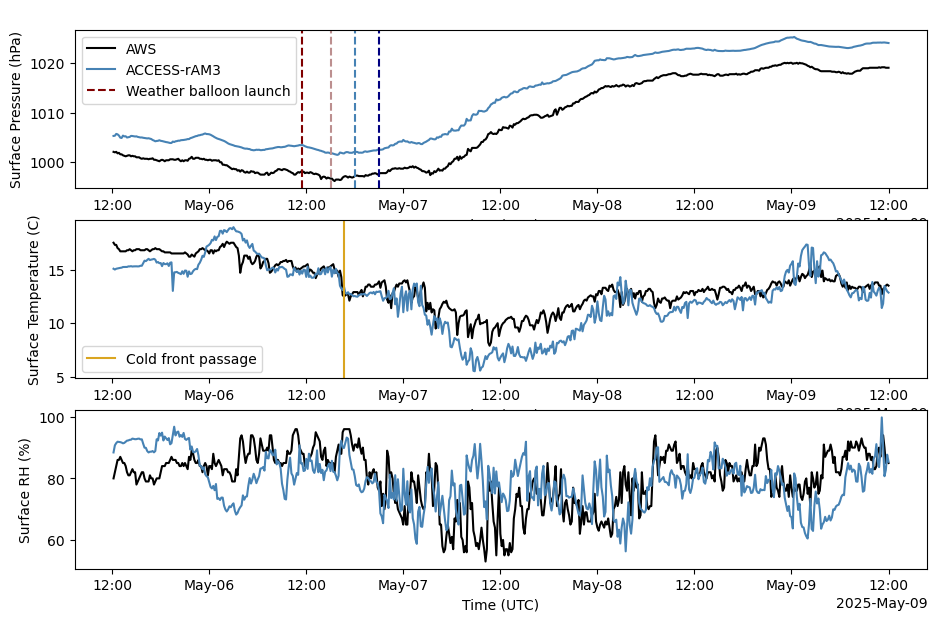

In [17]:
# Plot basic met data. 

fig = plt.figure(figsize=(11,7))
colors = ['maroon','rosybrown','steelblue','navy']

# plot pressure 
ax1 = plt.subplot(311)
aws['atmospheric_pressure'].plot(color='black',label='AWS')
(sfc_pres['pressure']/100).plot(color='steelblue',label='ACCESS-rAM3')
plt.ylabel('Surface Pressure (hPa)')
plt.xlabel('Time (UTC)')
plt.title(' ')

# add times where we have sondes 
for i,f in enumerate(sorted(files)):
    sonde = xr.open_mfdataset(f,engine="scipy")
    if i == 0: 
        plt.axvline(sonde.time[0].values,color=colors[i],linestyle='--',label='Weather balloon launch')
    else:
        plt.axvline(sonde.time[0].values,color=colors[i],linestyle='--',label=None)

plt.legend()

# plot temperature 
ax2 = plt.subplot(312,sharex=ax1)
aws['atmospheric_temperature'].plot(color='black',label=None)
(sfc_temp['sfc_temp']-273).plot(color='steelblue',label=None)
plt.ylabel('Surface Temperature (C)')
plt.xlabel('Time (UTC)')
plt.axvline(sfc_temp.time.sel(time='2025-05-06 16:40').values,label='Cold front passage',color='goldenrod') # indicates cold front passage at station
plt.title(' ')
plt.legend()

# Plot humidity 
ax3 = plt.subplot(313,sharex=ax1)
aws['atmospheric_relative_humidity'].plot(color='black')
(sfc_RH).plot(color='steelblue')
plt.ylabel('Surface RH (%)')
plt.xlabel('Time (UTC)')
plt.title(' ');

# Weather Balloons
Here we compare the model meteorology compared to the weather baloon data. I've just dones so for the for soundings near the cold front

### Things to try: 
- Plot all the soundings. Does it look messy? How could we divide up the data to make it look coherent
- Plot the wind profiles
- Plot the dew point temperature 

In [18]:
# read in the relevant model data - this time need full verticle model heights 
temp = xr.open_mfdataset(data_dir+'*/Southern_Ocean_ERA5to1km_d0100_RAL3P3/PMET/air_temp-Southern_Ocean_ERA5to1km_d0100_RAL3P3-v1-*.nc',preprocess=preprocess)
spec_hum = xr.open_mfdataset(data_dir+'*/Southern_Ocean_ERA5to1km_d0100_RAL3P3/PMET/spec_hum-Southern_Ocean_ERA5to1km_d0100_RAL3P3-v1-*.nc',preprocess=preprocess)
press = xr.open_mfdataset(data_dir+'*/Southern_Ocean_ERA5to1km_d0100_RAL3P3/PMET/pressure-Southern_Ocean_ERA5to1km_d0100_RAL3P3-v1-*.nc',preprocess=preprocess)

/jobfs/182535723.gadi-pbs/ipykernel_2755204/4237515804.py:2: FutureWarning: In a future version, xarray will not decode the variable 'forecast_period' into a timedelta64 dtype based on the presence of a timedelta-like 'units' attribute by default. Instead it will rely on the presence of a timedelta64 'dtype' attribute, which is now xarray's default way of encoding timedelta64 values.
To continue decoding into a timedelta64 dtype, either set `decode_timedelta=True` when opening this dataset, or add the attribute `dtype='timedelta64[ns]'` to this variable on disk.
To opt-in to future behavior, set `decode_timedelta=False`.
  temp = xr.open_mfdataset(data_dir+'*/Southern_Ocean_ERA5to1km_d0100_RAL3P3/PMET/air_temp-Southern_Ocean_ERA5to1km_d0100_RAL3P3-v1-*.nc',preprocess=preprocess)
/jobfs/182535723.gadi-pbs/ipykernel_2755204/4237515804.py:2: FutureWarning: In a future version, xarray will not decode the variable 'forecast_period' into a timedelta64 dtype based on the presence of a timedel

In [19]:
# need to calcualte the relative humidity again 

q = spec_hum['spec_hum']      # kg/kg
p = press['pressure'] / 100.0 # hPa
T_c = temp['air_temp'] - 273.15 # C

# Vapor pressure (hPa)
e = q * p / (0.622 + 0.378 * q)

# Saturation vapor pressure (hPa)
es = 6.112 * np.exp((17.67 * T_c) / (T_c + 243.5))

# Relative humidity (%)
RH = 100.0 * e / es


In [20]:
# List of sondes to read in: 

#files = glob("/g/data/jk72/slf563/OBS/campaigns/CAPE-K/kcgsondewnpnM1.b1/*.cdf") # All files 
files=['/g/data/jk72/slf563/OBS/campaigns/CAPE-K/kcgsondewnpnM1.b1/kcgsondewnpnM1.b1.20250506.113000.cdf',
       '/g/data/jk72/slf563/OBS/campaigns/CAPE-K/kcgsondewnpnM1.b1/kcgsondewnpnM1.b1.20250506.150000.cdf',
       '/g/data/jk72/slf563/OBS/campaigns/CAPE-K/kcgsondewnpnM1.b1/kcgsondewnpnM1.b1.20250506.180000.cdf',
       '/g/data/jk72/slf563/OBS/campaigns/CAPE-K/kcgsondewnpnM1.b1/kcgsondewnpnM1.b1.20250506.210000.cdf',]


In [21]:
# read in just one sonde to take a look at the data
sonde = xr.open_mfdataset(files[0],engine="scipy")
sonde

<xarray.Dataset> Size: 159kB
Dimensions:      (time: 1531)
Coordinates:
  * time         (time) datetime64[ns] 12kB 2025-05-06T11:30:00 ... 2025-05-0...
Data variables: (12/24)
    base_time    datetime64[ns] 8B ...
    time_offset  (time) datetime64[ns] 12kB dask.array<chunksize=(1531,), meta=np.ndarray>
    pres         (time) float32 6kB dask.array<chunksize=(1531,), meta=np.ndarray>
    qc_pres      (time) int32 6kB dask.array<chunksize=(1531,), meta=np.ndarray>
    tdry         (time) float32 6kB dask.array<chunksize=(1531,), meta=np.ndarray>
    qc_tdry      (time) int32 6kB dask.array<chunksize=(1531,), meta=np.ndarray>
    ...           ...
    wstat        (time) float32 6kB dask.array<chunksize=(1531,), meta=np.ndarray>
    asc          (time) float32 6kB dask.array<chunksize=(1531,), meta=np.ndarray>
    qc_asc       (time) int32 6kB dask.array<chunksize=(1531,), meta=np.ndarray>
    lat          (time) float32 6kB dask.array<chunksize=(1531,), meta=np.ndarray>
    lon          (time) float32 6kB dask.array<chunksize=(1531,), meta=np.ndarray>
    alt          (time) float32 6kB dask.array<chunksize=(1531,), meta=np.ndarray>
Attributes: (12/32)
    command_line:               sonde_ingest -s kcg -f M1
    Conventions:                ARM-1.2
    process_version:            ingest-sonde-10.15-1.el7
    dod_version:                sondewnpn-b1-2.3
    input_source:               /data/collection/kcg/kcgsondeM1.00/kcgsonde-c...
    site_id:                    kcg
    ...                         ...
    latitude_calculation:       lat[k-1]+((v_wind[k]-v_wind[k-1])/2)*delta_ti...
    longitude_calculation:      lon[k-1]+((u_wind[k]-u_wind[k-1])/2)*delta_ti...
    sonde_pc_software_version:  2.17
    sounding_number:            ///
    doi:                        10.5439/1595321
    history:                    created by user dsmgr on machine prod-proc3.a...

In [ ]:
fig = plt.figure(figsize=(11,7))

colors = ['maroon','rosybrown','steelblue','navy'] # have coloured the sondes from red to blue: warm to cold 
labels = ['2025-05-06 11:30','2025-05-06 15:00','2025-05-06 18:00','2025-05-06 21:00']

for i,f in enumerate(files):

    sonde = xr.open_mfdataset(f,engine="scipy")

    # plot temperature profiles 
    ax1 = plt.subplot(121)

    ax1.plot(temp['air_temp'].sel(time = sonde.time[0],method='nearest')-273,temp['level_height'],alpha=1,color=colors[i],
             linestyle='--',label=labels[i])
    ax1.plot(sonde.tdry,sonde.alt,alpha=1, color=colors[i],linestyle='-')
    
    plt.ylim(0,5000)
    plt.xlim(-20,20)
    plt.ylabel('Height (m)')
    plt.xlabel('Temperature (C)')

    plt.legend()

    # plot humidity profiles 
    ax3 = plt.subplot(122)

    ax3.plot(RH.sel(time = sonde.time[0],method='nearest'),temp['level_height'],alpha=1,color=colors[i],linestyle='--',label='Model')
    ax3.plot(sonde.rh,sonde.alt,alpha=1, color=colors[i],linestyle='-',label='Obs')
    plt.ylim(0,5000)
    plt.ylabel('Height (m)')
    plt.xlabel('RH (%)')
    if i == 0: 
        plt.legend()


# Whats next? 
- Run some basic statistics: mean, standard deviations, RMSE, correlations comparing the modelled met to the observed....
- Think about how we can divide up this data in to useful periods of time. By cloud type? Air mass origin? How would we figure that out? 
- Read up about skew-t diagrams and what they mean for cloud formation and atmospheric instability. <https://www.bom.gov.au/aviation/data/education/RM-SkewT.pdf>. Maybe you can even try to plot one <https://unidata.github.io/MetPy/latest/api/generated/metpy.plots.SkewT.html> (start with: `import metpy`)
- We should do the exact same analysis but with the COAST-K data. You will need to work out how to extract the model data along the ship track - the lat/lon change with time steps. We can provide you code for that when you are ready. The met data is in the underway files, but we will need to find the sounding data.